## Test the heuristic layout design strategy

In [1]:
import os
import sys
sys.path.append("..")
import logging
logging.basicConfig(level=logging.WARN)

from qunoc.utils.utils import get_timestamp
from qunoc.element.package import *

result_dir = f"result/layout/heuristic/example_{get_timestamp()}"
os.makedirs(result_dir, exist_ok=True)

package = Package((100, 100), design_strategy="heuristic", result_dir=result_dir)

package.save_design_history()
package.save()
print("Package score:", package.estimate_score())

Package score: 5.7720744978874645


## Test the greedy layout design strategy

In [1]:
import os
import sys
sys.path.append("..")
import logging
logging.basicConfig(level=logging.WARN)

from qunoc.utils.utils import get_timestamp
from qunoc.element.package import *

result_dir = f"result/layout/greedy/example_{get_timestamp()}"
os.makedirs(result_dir, exist_ok=True)

package = Package((50, 50), FabricateModel(20, 10), design_strategy="greedy", result_dir=result_dir)
# package = Package(design_strategy="greedy", result_dir=result_dir)

package.save_design_history()
package.save()
print("Package score:", package.estimate_score())

Package score: 22.319211292918688


In [2]:
import os
import sys
sys.path.append("..")
import logging
logging.basicConfig(level=logging.INFO)

from qunoc.element.package import *

result_dir = f"../evaluate/result/layout_scalability/package_size/100_100_greedy"
package = Package(pre_designed_package_path=os.path.join(result_dir, "package.pkl"))
print("Package score:", package.estimate_score())

Package score: 17.14548024225324


## Test the rl-based layout design strategy

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Training agent...


KeyboardInterrupt: 

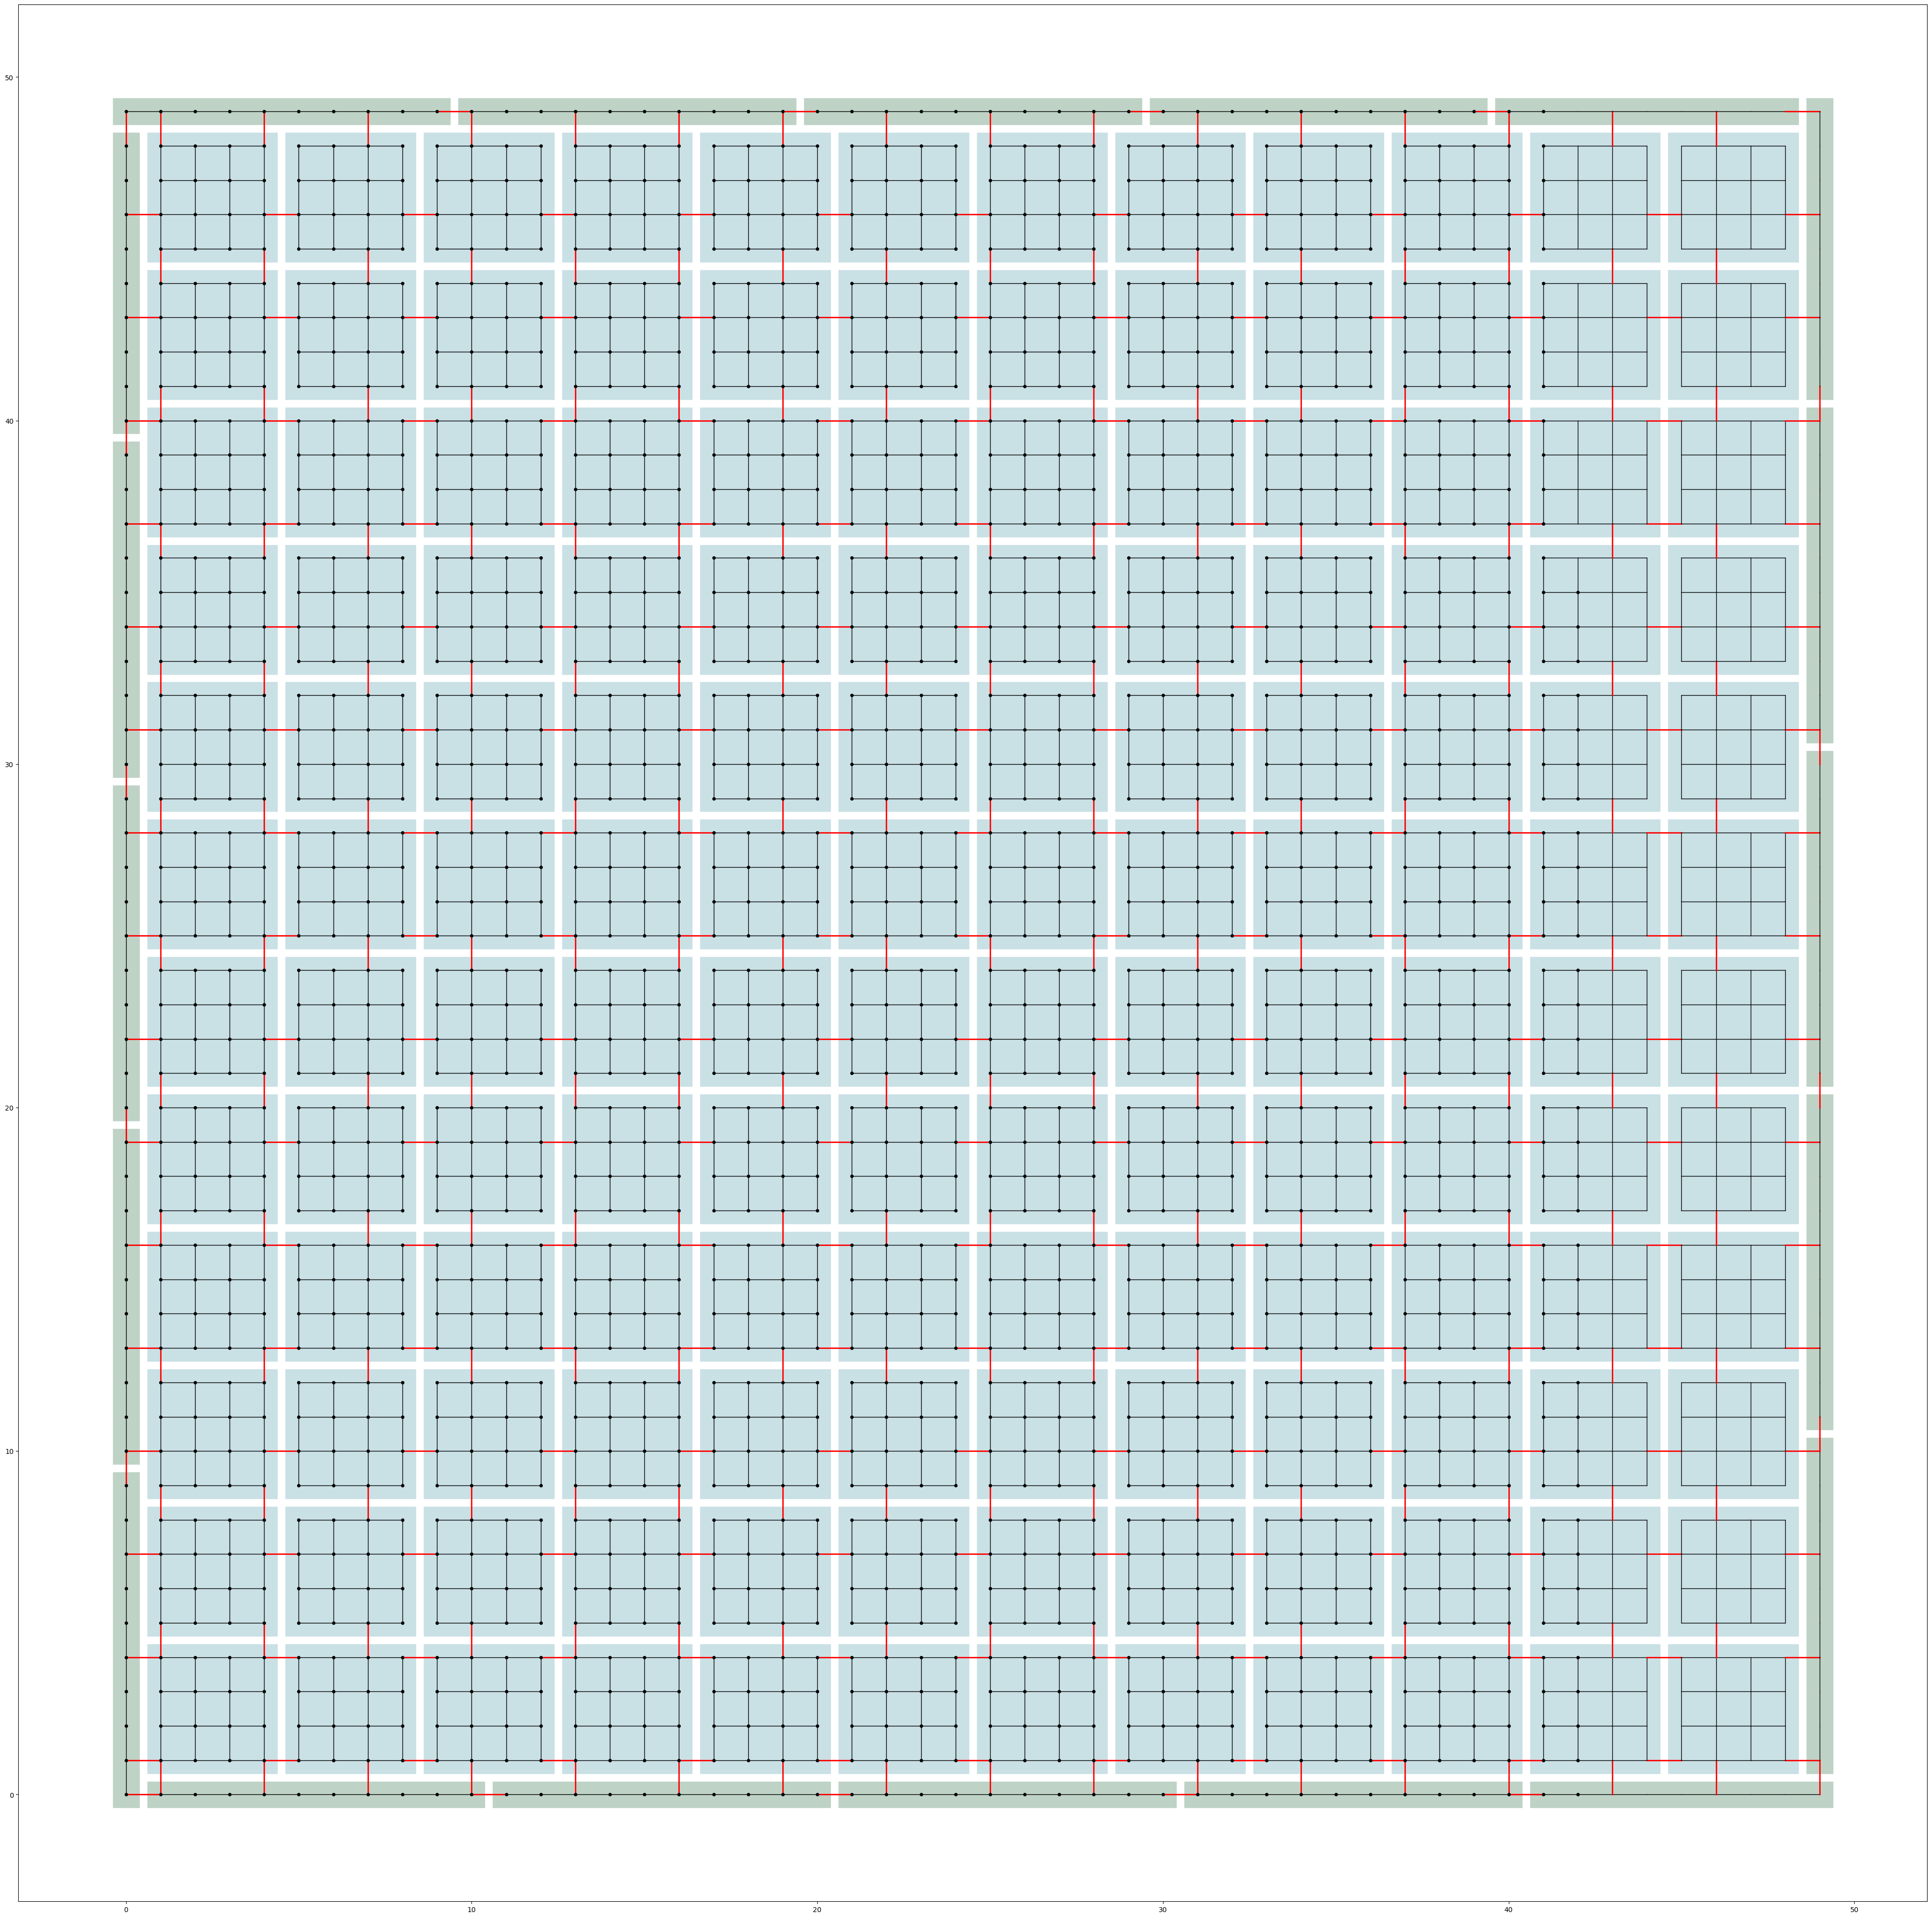

In [3]:
import os
import sys
sys.path.append("..")
import logging
logging.basicConfig(level=logging.WARN)

from qunoc.utils.utils import get_timestamp
from qunoc.element.package import *
from qunoc.layout.env import QuNoCEnv
from qunoc.layout.agent import LayoutAgent

result_dir = f"result/layout/rl/example_{get_timestamp()}"
os.makedirs(result_dir, exist_ok=True)

env = QuNoCEnv((50, 50), FabricateModel(20, 10), result_dir=result_dir)
# env = QuNoCEnv(result_dir=result_dir)
agent = LayoutAgent(env, result_dir=result_dir)
agent.train(1000)
package = agent.design()

package.save_design_history()
package.save()
print("Package score:", package.estimate_score())

## Test the benchmark generation

In [ ]:
import os
import sys
sys.path.append("..")
import logging
logging.basicConfig(level=logging.WARN)

from qunoc.element.benchmark import *

vqe_program = vqe(5)
print(vqe_program)
qft_program = qft(5)
print(qft_program)
qaoa_program = qaoa(5)
print(qaoa_program)
bv_program = bv(5)
print(bv_program)

vqe program: Control_0_1, Control_0_2, Control_0_3, Control_0_4, Control_1_2, Control_1_3, Control_1_4, Control_2_3, Control_2_4, Control_3_4
qft program: Control_1_0, Control_2_0, Control_3_0, Control_2_1, Control_4_0, Control_3_1, Control_4_1, Control_3_2, Control_4_2, Control_4_3
qaoa program: Control_2_4, Control_3_4, Control_0_2, Control_1_4, Control_1_2
bv program: Control_0_3, Control_0_4


## Test the routing algorithm

In [ ]:
import os
import sys
sys.path.append("..")

from qunoc.utils.utils import get_timestamp
from qunoc.element.package import *
from qunoc.element.benchmark import *

algo = "qft"
data_qubit_num = 16

# result_dir = f"result/routing/example_{get_timestamp()}"
result_dir = f"result/routing/example_{algo}_{data_qubit_num}"
os.makedirs(result_dir, exist_ok=True)

import logging
for handler in logging.root.handlers[:]:
    logging.root.removeHandler(handler)
logging.basicConfig(
    filename=os.path.join(result_dir, "log.txt"),
    filemode='w',
    format="%(asctime)s - %(levelname)s - %(message)s",
    level=logging.INFO,
    encoding="utf-8"
)

package = Package(package_size=(9, 9), fab_model=FabricateModel(9, 9), design_strategy="manual", result_dir=result_dir)
package.design_module_top_down(package.compute_modules[0], DesignTemplate.Grid, DesignOrientation.X, 3)

package.save_design_history()
package.save()
print("Package score:", package.estimate_score())

program = get_program(algo, data_qubit_num)
gate_depend_fig = program.draw_depend()
gate_depend_fig.savefig(os.path.join(result_dir, f"{program.algo_name}_{program.data_qubit_num}_gate_depend.png"), bbox_inches="tight")
qiskit_circuit_fig = program.draw_circuit()
qiskit_circuit_fig.savefig(os.path.join(result_dir, f"{program.algo_name}_{program.data_qubit_num}_qiskit_circuit.png"), bbox_inches="tight")
print("Program gate num:", program.gate_depend_graph.number_of_nodes())

Package score: 43.05567281103211
Program gate num: 121


In [ ]:
from qunoc.utils.config import config
from qunoc.routing.router import *

config.debug_mapping = True
config.debug_block = True
config.debug_action = True
router = Router(package, program, result_dir=result_dir)
router.map_qubits()
print(f"Routing program {program.algo_name}-{program.data_qubit_num}")

Routing program qft-16


In [ ]:
router.compile_blocks_and_actions()
router.save_block_history()
block_depend_fig = router.draw_block_depend()
block_depend_fig.savefig(os.path.join(result_dir, f"{program.algo_name}_{program.data_qubit_num}_block_depend.png"), bbox_inches="tight")
print("Block depth:", router.get_block_depth(), ", block count:", router.block_depend_graph.number_of_nodes())

Block depth: 22 , block count: 59


In [ ]:
try:
    router.schedule_actions_to_circuit()
except AssertionError:
    router.save_action_history()
    raise
router.save_action_history()
action_depend_fig = router.draw_action_depend()
action_depend_fig.savefig(os.path.join(result_dir, f"{program.algo_name}_{program.data_qubit_num}_action_depend.png"), bbox_inches="tight")
print("Action depth:", router.get_action_depth(), ", action count:", router.action_depend_graph.number_of_nodes())
circuit = router.circuit
circuit.to_pickle(os.path.join(result_dir, f"{program.algo_name}_{program.data_qubit_num}_qunoc_circuit.pkl"))
print("QuNoC gate fidelity:", router.estimate_qunoc_logic_gate_fide(), ", QuNoC circuit depth:", router.estimate_qunoc_circuit_duration())

Action depth: 353 , action count: 885
QuNoC gate fidelity: 0.8413625755790922 , QuNoC circuit depth: 29123.785842495003


## Test the immediate-schedule routing

In [ ]:
import os
import sys
sys.path.append("..")

from qunoc.utils.utils import get_timestamp
from qunoc.element.package import *
from qunoc.element.benchmark import *

algo = "vqe"
data_qubit_num = 16

# result_dir = f"result/routing/example_{get_timestamp()}"
result_dir = f"result/routing/example_{algo}_{data_qubit_num}"
os.makedirs(result_dir, exist_ok=True)

import logging
for handler in logging.root.handlers[:]:
    logging.root.removeHandler(handler)
logging.basicConfig(
    filename=os.path.join(result_dir, "log.txt"),
    filemode='w',
    format="%(asctime)s - %(levelname)s - %(message)s",
    level=logging.INFO,
    encoding="utf-8"
)

package = Package(package_size=(9, 9), fab_model=FabricateModel(9, 9), design_strategy="manual", result_dir=result_dir)
package.design_module_top_down(package.compute_modules[0], DesignTemplate.Grid, DesignOrientation.X, 3)

package.save_design_history()
package.save()
print("Package score:", package.estimate_score())

program = get_program(algo, data_qubit_num)
gate_depend_fig = program.draw_depend()
gate_depend_fig.savefig(os.path.join(result_dir, f"{program.algo_name}_{program.data_qubit_num}_gate_depend.png"), bbox_inches="tight")
qiskit_circuit_fig = program.draw_circuit()
qiskit_circuit_fig.savefig(os.path.join(result_dir, f"{program.algo_name}_{program.data_qubit_num}_qiskit_circuit.png"), bbox_inches="tight")
print("Program gate num:", program.gate_depend_graph.number_of_nodes())

Package score: 41.08503860302223
Program gate num: 121


In [ ]:
from qunoc.utils.config import config
from qunoc.routing.router import *

config.debug_mapping = True
config.debug_block = True
config.debug_action = True
router = Router(package, program, result_dir=result_dir)
router.map_qubits()
print(f"Routing program {program.algo_name}-{program.data_qubit_num}")

Routing program vqe-16


In [ ]:
try:
    router.compile_blocks_and_schedule_actions()
except AssertionError:
    router.save_action_history()
    raise
router.save_block_history()
# block_depend_fig = router.draw_block_depend()
# block_depend_fig.savefig(os.path.join(result_dir, f"{program.algo_name}_{program.data_qubit_num}_block_depend.png"), bbox_inches="tight")
# print("Block depth:", router.get_block_depth(), ", block count:", router.block_depend_graph.number_of_nodes())
router.save_action_history()
# action_depend_fig = router.draw_action_depend()
# action_depend_fig.savefig(os.path.join(result_dir, f"{program.algo_name}_{program.data_qubit_num}_action_depend.png"), bbox_inches="tight")
# print("Action depth:", router.get_action_depth(), ", action count:", router.action_depend_graph.number_of_nodes())
circuit = router.circuit
circuit.to_pickle(os.path.join(result_dir, f"{program.algo_name}_{program.data_qubit_num}_qunoc_circuit.pkl"))
print("QuNoC gate fidelity:", router.estimate_qunoc_logic_gate_fide(), ", QuNoC circuit depth:", router.estimate_qunoc_circuit_duration())

QuNoC gate fidelity: 0.8565807339481267 , QuNoC circuit depth: 84711.07305890125


## Test the baseline MECH

In [ ]:
import os
import sys
sys.path.append("..")
import math

from baseline.MECH.MECHBenchmarks import *
import json
%load_ext autoreload
%autoreload 2

In [ ]:
structure="square"
chiplet_array_dim=(3,3)
chiplet_size=(10,10)
benchmarks=["qaoa"]
data_qubit_num = math.prod(chiplet_array_dim) * math.prod(chiplet_size) // 100

exp_results = MECH_experiments(structure=structure, chiplet_array_dim=chiplet_array_dim, chiplet_size=chiplet_size, benchmarks=benchmarks, data_qubit_num=data_qubit_num, cross_link_sparsity=1)
print(exp_results)

18/36 gates are selected: [(0, 2), (0, 6), (0, 7), (0, 8), (1, 2), (1, 3), (1, 7), (2, 3), (2, 4), (2, 5)]...[(2, 4), (2, 5), (2, 7), (3, 8), (4, 6), (4, 7), (5, 6), (5, 7), (6, 7), (6, 8)]
----------------executing  qaoa
0/7
defaultdict(<class 'dict'>, {'qaoa': {'depth': 120, 'eff_gate_num': 1434.4, 'on_chip': 612, 'cross_chip': 27, 'meas_num': 283, 'weight': (7.4, 2.2), 'periods': (13, 2), 'shuttle_num': 6, 'sparsity': 1, 'data_qubit_num': 9, 'gate_num': 36}})


In [ ]:
structure_abbr = '_'.join([s[:3] for s in structure.split('_')])
file_path = "./result/baseline/mech/{}{}{}{}{}.json".format(structure_abbr, chiplet_array_dim[0], chiplet_array_dim[1], chiplet_size[0], chiplet_size[1])
os.makedirs(os.path.dirname(file_path), exist_ok=True)

with open(file_path, 'w') as json_file:
    json.dump(exp_results, json_file)

print(f"The dictionary has been written to {file_path}")

The dictionary has been written to ./result/baseline/mech/squ331010.json


In [ ]:
from baseline.utils.utils import get_mech_circuit_duration, get_mech_logic_gate_fide

for b in benchmarks:
    mech_gate_fidelity = get_mech_logic_gate_fide(exp_results[b], chiplet_size=chiplet_size)
    mech_circuit_depth = get_mech_circuit_duration(exp_results[b])
    print("Program", b+'-'+str(exp_results[b]["data_qubit_num"]), ", gate num:", exp_results[b]["gate_num"], ", MECH gate fidelity:", mech_gate_fidelity, ", MECH circuit depth:", mech_circuit_depth)

Program qaoa-9 , gate num: 36 , MECH gate fidelity: 0.8092953742596113 , MECH circuit depth: 273600


## Debug evaluation

In [ ]:
import os
import sys
sys.path.append("..")
import json

from qunoc.element.package import *
from qunoc.element.benchmark import *
from qunoc.routing.router import *
from qunoc.utils.config import config
from baseline.MECH.MECHBenchmarks import MECH_experiments
from baseline.utils.utils import get_mech_circuit_duration, get_mech_logic_gate_fide

algorithm = "vqe"
package_length = 40

# result_dir = f"result/routing/example_{get_timestamp()}"
result_dir = f"result/routing/example_{algorithm}_{package_length}_{package_length}"
os.makedirs(result_dir, exist_ok=True)

import logging
for handler in logging.root.handlers[:]:
    logging.root.removeHandler(handler)
logging.basicConfig(
    filename=os.path.join(result_dir, "log.txt"),
    filemode='w',
    format="%(asctime)s - %(levelname)s - %(message)s",
    level=logging.INFO,
    encoding="utf-8"
)

config.debug_mapping = True
config.debug_block = True
config.debug_action = True

package_size = (package_length, package_length)
node_num = math.prod(package_size)
if node_num < 100:
    data_qubit_num = node_num // 100
else:
    data_qubit_num = node_num // 100


if package_length < 100:
    chiplet_array_dim = (package_length // 10, package_length // 10)
    chiplet_size = (10, 10)
else:
    chiplet_array_dim = (package_length // 20, package_length // 20)
    chiplet_size = (20, 20)
exp_result_dict = MECH_experiments(structure="square", chiplet_array_dim=chiplet_array_dim, chiplet_size=chiplet_size, benchmarks=[algorithm], data_qubit_num=data_qubit_num, cross_link_sparsity=3)
exp_result = exp_result_dict[algorithm]
with open(os.path.join(result_dir, "mech_exp_result.json"), 'w') as json_file:
    json.dump(exp_result, json_file)
circuit_depth = get_mech_circuit_duration(exp_result)
gate_fidelity = get_mech_logic_gate_fide(exp_result, (10, 10))
print("MECH gate fidelity:", gate_fidelity, ", MECH circuit depth:", circuit_depth)
print("MECH exp result:", exp_result)

package = Package(pre_designed_package_path=os.path.join("../evaluate/result/layout_scalability/package_size", f"{package_length}_{package_length}_greedy/package.pkl"))
program = get_program(algorithm, data_qubit_num)
router = Router(package, program, result_dir=result_dir)
circuit = router.route_program_on_package()
print("QuNoC gate fidelity:", router.estimate_qunoc_logic_gate_fide(), ", QuNoC circuit depth:", router.estimate_qunoc_circuit_duration())
intra_gate_num, inter_gate_num, qst_dist, meas_num, total_fide = router.statistic_route_results()
exp_result = {
    "circuit_duration": circuit_depth,
    "intra_gate": intra_gate_num,
    "inter_gate": inter_gate_num, 
    "qst_dist": qst_dist, 
    'meas_num': meas_num, 
    'sparsity': FabricateModel().inter_sparsity, 
    'data_qubit_num': data_qubit_num,
    'gate_num': program.get_gate_depend_graph().number_of_nodes() - 1
}
with open(os.path.join(result_dir, "qunoc_exp_result.json"), 'w') as json_file:
    json.dump(exp_result, json_file)
print("QuNoC exp result:", exp_result)



60/120 gates are selected: [(0, 2), (0, 3), (0, 4), (0, 5), (0, 10), (0, 12), (0, 13), (0, 14), (1, 2), (1, 3)]...[(9, 12), (9, 13), (9, 14), (10, 13), (10, 14), (11, 12), (11, 14), (12, 13), (12, 15), (14, 15)]
----------------executing  vqe
0/15
10/15
MECH gate fidelity: 0.7869816122526582 , MECH circuit depth: 585960
MECH exp result: {'depth': 257, 'eff_gate_num': 5699.8, 'on_chip': 2261, 'cross_chip': 135, 'meas_num': 1109, 'weight': (7.4, 2.2), 'periods': (13, 2), 'shuttle_num': 15, 'sparsity': 3, 'data_qubit_num': 16, 'gate_num': 120}
QuNoC gate fidelity: 0.8073076060116552 , QuNoC circuit depth: 214402.347538298
QuNoC exp result: {'circuit_depth': 585960, 'intra_gate': 300, 'inter_gate': 853, 'qst_dist': 4329, 'meas_num': 135, 'sparsity': 3, 'data_qubit_num': 16, 'gate_num': 120}
